<a href="https://colab.research.google.com/github/Pappas313/SQLAlchemy/blob/main/Advanced_Google_Colab_Project_Financial_Risk_Analytics_Platform.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Advanced Google Colab Project: Financial Risk Analytics Platform**

Let's build a more advanced, realistic Banking Transaction & Fraud Detection System using SQLAlchemy 2.0, PostgreSQL-compatible ORM models, Pandas, Scikit-learn, and Plotly.

This project is suitable for a Senior Python Developer, Data Engineer, or Backend Engineer portfolio.

**Project architecture**

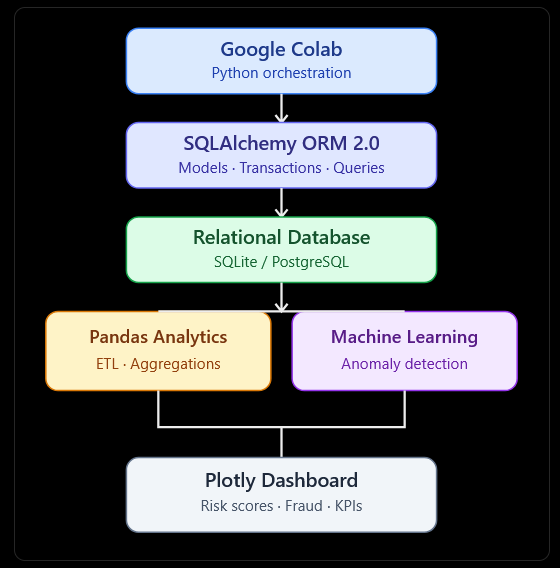

**What you will build**

•	Five connected database tables: Customers, Accounts, Merchants, Transactions, Fraud Alerts.

•	Generate 20,000 realistic synthetic financial transactions.

•	Use SQLAlchemy 2.0 with typed models, relationships, indexes, and database constraints.

•	Perform SQL aggregation, JOINs, window functions, and analytical queries.

•	Detect unusual transactions using Isolation Forest.

•	Save risk scores and alerts back into the database.

•	Create an interactive financial dashboard using Plotly.

**Database:** SQLite for a zero-configuration Colab experience, with a design that can be migrated to PostgreSQL.


**Phase 1 — Environment and database setup**

**Step 1.** Install required Python libraries

In [ ]:

!pip -q install "sqlalchemy>=2.0,<3" pandas numpy scikit-learn plotly


**Notes**

**Library	Purpose**

SQLAlchemy	ORM, SQL queries, database transactions

Pandas	Data analysis and transformation

NumPy	Numerical calculations

Scikit-learn	Fraud anomaly detection

Plotly	Interactive dashboards

SQLite	Relational database built into Python

**Step 2.** Import dependencies


In [ ]:

import random
import numpy as np
import pandas as pd
import plotly.express as px

from datetime import datetime, timedelta, timezone
from decimal import Decimal

from sqlalchemy import (
    create_engine,
    ForeignKey,
    String,
    Numeric,
    DateTime,
    Integer,
    Index,
    CheckConstraint,
    select,
    func,
    case,
    text
)

from sqlalchemy.orm import (
    DeclarativeBase,
    Mapped,
    mapped_column,
    relationship,
    sessionmaker,
    selectinload
)

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

random.seed(42)
np.random.seed(42)

print("All libraries imported successfully")


All libraries imported successfully


**Notes:** We use modern SQLAlchemy 2.0 syntax with Mapped, mapped_column, and DeclarativeBase. Decimal and Numeric are used for monetary values instead of floating-point database columns.

**Step 3.** Create a database engine

In [ ]:

DATABASE_URL = "sqlite:///financial_risk.db"

engine = create_engine(
    DATABASE_URL,
    echo=False,
    pool_pre_ping=True
)

class Base(DeclarativeBase):
    pass

SessionLocal = sessionmaker(
    bind=engine,
    expire_on_commit=False
)

with engine.connect() as conn:
    result = conn.execute(
        text("SELECT sqlite_version()")
    )
    print("SQLite version:", result.scalar())


SQLite version: 3.45.1


**Notes**

•	create_engine() creates the database connection infrastructure.

•	SessionLocal produces sessions for querying and modifying data.

•	pool_pre_ping=True checks pooled connections before use.

•	echo=True is useful when you want to inspect generated SQL.

The database is stored in the temporary Colab runtime. It will not survive a runtime reset unless you persist it elsewhere.

**Phase 2** — Database design

We will create five relational tables.


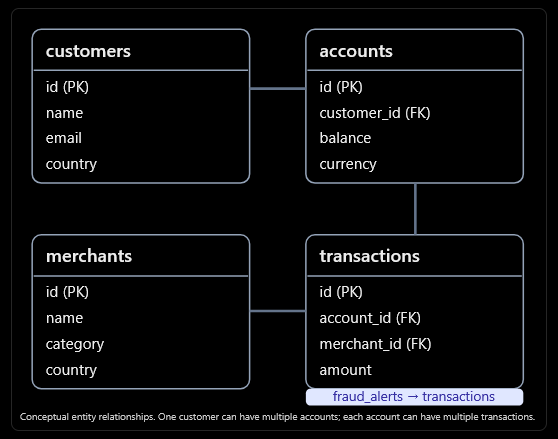

**Step 4. Define the ORM models**

In [ ]:

class Customer(Base):
    __tablename__ = "customers"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    email: Mapped[str] = mapped_column(
        String(180), unique=True
    )
    country: Mapped[str] = mapped_column(String(2))

    accounts: Mapped[list["Account"]] = relationship(
        back_populates="customer"
    )


class Account(Base):
    __tablename__ = "accounts"

    id: Mapped[int] = mapped_column(primary_key=True)
    customer_id: Mapped[int] = mapped_column(
        ForeignKey("customers.id"), index=True
    )
    balance: Mapped[Decimal] = mapped_column(
        Numeric(18, 2), default=Decimal("0.00")
    )
    currency: Mapped[str] = mapped_column(
        String(3), default="EUR"
    )

    customer: Mapped["Customer"] = relationship(
        back_populates="accounts"
    )
    transactions: Mapped[list["Transaction"]] = relationship(
        back_populates="account"
    )


class Merchant(Base):
    __tablename__ = "merchants"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    category: Mapped[str] = mapped_column(String(60))
    country: Mapped[str] = mapped_column(String(2))

    transactions: Mapped[list["Transaction"]] = relationship(
        back_populates="merchant"
    )


class Transaction(Base):
    __tablename__ = "transactions"

    id: Mapped[int] = mapped_column(primary_key=True)
    account_id: Mapped[int] = mapped_column(
        ForeignKey("accounts.id")
    )
    merchant_id: Mapped[int] = mapped_column(
        ForeignKey("merchants.id")
    )
    amount: Mapped[Decimal] = mapped_column(
        Numeric(18, 2)
    )
    created_at: Mapped[datetime] = mapped_column(
        DateTime(timezone=True)
    )
    status: Mapped[str] = mapped_column(
        String(20), default="completed"
    )

    account: Mapped["Account"] = relationship(
        back_populates="transactions"
    )
    merchant: Mapped["Merchant"] = relationship(
        back_populates="transactions"
    )
    alerts: Mapped[list["FraudAlert"]] = relationship(
        back_populates="transaction"
    )

    __table_args__ = (
        CheckConstraint(
            "amount > 0", name="ck_positive_amount"
        ),
        Index(
            "ix_transaction_account_date",
            "account_id", "created_at"
        ),
    )


class FraudAlert(Base):
    __tablename__ = "fraud_alerts"

    id: Mapped[int] = mapped_column(primary_key=True)
    transaction_id: Mapped[int] = mapped_column(
        ForeignKey("transactions.id"), unique=True
    )
    risk_score: Mapped[Decimal] = mapped_column(
        Numeric(8, 5)
    )
    severity: Mapped[str] = mapped_column(String(20))

    transaction: Mapped["Transaction"] = relationship(
        back_populates="alerts"
    )

Base.metadata.create_all(engine)

print("Created tables:")
print(list(Base.metadata.tables.keys()))


Created tables:
['customers', 'accounts', 'merchants', 'transactions', 'fraud_alerts']


**Important concepts**

•	Mapped[int] provides typed ORM mapping.

•	ForeignKey enforces references between tables.

•	relationship() allows object navigation.

•	CheckConstraint prevents invalid transaction amounts.

•	Index can accelerate queries filtering by account and date.

**Step 5**. Inspect the database schema


In [ ]:

from sqlalchemy import inspect

inspector = inspect(engine)

for table_name in inspector.get_table_names():
    print(f"\nTABLE: {table_name}")

    for column in inspector.get_columns(table_name):
        print(
            column["name"],
            column["type"],
            "Nullable:", column["nullable"]
        )



TABLE: accounts
id INTEGER Nullable: False
customer_id INTEGER Nullable: False
balance NUMERIC(18, 2) Nullable: False
currency VARCHAR(3) Nullable: False

TABLE: customers
id INTEGER Nullable: False
name VARCHAR(120) Nullable: False
email VARCHAR(180) Nullable: False
country VARCHAR(2) Nullable: False

TABLE: fraud_alerts
id INTEGER Nullable: False
transaction_id INTEGER Nullable: False
risk_score NUMERIC(8, 5) Nullable: False
severity VARCHAR(20) Nullable: False

TABLE: merchants
id INTEGER Nullable: False
name VARCHAR(120) Nullable: False
category VARCHAR(60) Nullable: False
country VARCHAR(2) Nullable: False

TABLE: transactions
id INTEGER Nullable: False
account_id INTEGER Nullable: False
merchant_id INTEGER Nullable: False
amount NUMERIC(18, 2) Nullable: False
created_at DATETIME Nullable: False
status VARCHAR(20) Nullable: False


This is useful for database debugging and schema validation.

**Phase 3** — Generate 20,000 financial transactions

**Step 6.** Insert customers, accounts and merchants

In [ ]:

# Reset existing sample data so this cell is repeatable
with SessionLocal.begin() as session:
    session.query(FraudAlert).delete()
    session.query(Transaction).delete()
    session.query(Account).delete()
    session.query(Merchant).delete()
    session.query(Customer).delete()

countries = ["GR", "DE", "FR", "GB", "US"]
categories = [
    "Retail", "Travel", "Food",
    "Electronics", "Entertainment"
]

with SessionLocal.begin() as session:
    customers = [
        Customer(
            name=f"Customer {i}",
            email=f"customer{i}@example.com",
            country=random.choice(countries)
        )
        for i in range(1, 501)
    ]

    session.add_all(customers)
    session.flush()

    accounts = [
        Account(
            customer_id=customer.id,
            balance=Decimal("10000.00"),
            currency="EUR"
        )
        for customer in customers
    ]

    merchants = [
        Merchant(
            name=f"Merchant {i}",
            category=random.choice(categories),
            country=random.choice(countries)
        )
        for i in range(1, 101)
    ]

    session.add_all(accounts + merchants)

print("500 customers created")
print("500 accounts created")
print("100 merchants created")


500 customers created
500 accounts created
100 merchants created


**Notes:**
session.flush() sends pending inserts to the database and populates generated primary keys without committing the transaction.
SessionLocal.begin() automatically commits on success and rolls back on error.

**Step 7.** Generate realistic transaction data
We'll simulate mostly ordinary payments with a small proportion of unusually large transactions.

In [ ]:

with SessionLocal() as session:
    account_ids = list(
        session.scalars(select(Account.id))
    )
    merchant_ids = list(
        session.scalars(select(Merchant.id))
    )

transactions = []
now = datetime.now(timezone.utc).replace(tzinfo=None)

for i in range(20000):
    # 2% simulated unusual transactions
    unusual = random.random() < 0.02

    if unusual:
        amount = random.uniform(3000, 12000)
    else:
        amount = random.lognormvariate(4.0, 0.9)

    tx = Transaction(
        account_id=random.choice(account_ids),
        merchant_id=random.choice(merchant_ids),
        amount=Decimal(f"{amount:.2f}"),
        created_at=now - timedelta(
            days=random.randint(0, 89),
            hours=random.randint(0, 23),
            minutes=random.randint(0, 59)
        ),
        status="completed"
    )

    transactions.append(tx)

with SessionLocal.begin() as session:
    session.add_all(transactions)

print(f"Inserted {len(transactions):,} transactions")


Inserted 20,000 transactions


**Notes:** The lognormal distribution produces many small purchases and fewer large purchases. This is synthetic demonstration data, not a statistically validated model of real banking transactions.

**Step 8.** Verify database records

In [ ]:

with SessionLocal() as session:
    for model in [
        Customer, Account, Merchant,
        Transaction, FraudAlert
    ]:
        count = session.scalar(
            select(func.count()).select_from(model)
        )
        print(f"{model.__tablename__}: {count:,}")


customers: 500
accounts: 500
merchants: 100
transactions: 20,000
fraud_alerts: 0


**Phase 4 — Advanced SQLAlchemy queries**

**Step 9. JOIN three tables**

Retrieve transaction details along with customer and merchant information.

In [ ]:

stmt = (
    select(
        Transaction.id,
        Customer.name.label("customer"),
        Merchant.name.label("merchant"),
        Merchant.category,
        Transaction.amount,
        Transaction.created_at
    )
    .join(Account, Transaction.account_id == Account.id)
    .join(Customer, Account.customer_id == Customer.id)
    .join(Merchant, Transaction.merchant_id == Merchant.id)
    .order_by(Transaction.amount.desc())
    .limit(20)
)

with SessionLocal() as session:
    rows = session.execute(stmt).mappings().all()

df_join = pd.DataFrame(rows)
display(df_join)


,amount,category,created_at,customer,id,merchant
0,11994.86,Food,2026-08-11 15:06:26.735783,Customer 495,395,Merchant 48
1,11980.60,Electronics,2026-10-19 16:53:26.735783,Customer 371,19253,Merchant 10
2,11911.43,Electronics,2026-09-09 17:57:26.735783,Customer 249,11827,Merchant 30
3,11820.44,Travel,2026-08-19 10:14:26.735783,Customer 78,7029,Merchant 88
4,11748.42,Travel,2026-09-01 16:25:26.735783,Customer 186,9859,Merchant 100
5,11708.95,Travel,2026-09-24 03:10:26.735783,Customer 492,2326,Merchant 100
6,11708.87,Electronics,2026-10-13 07:56:26.735783,Customer 158,14620,Merchant 13
7,11702.81,Entertainment,2026-10-05 05:50:26.735783,Customer 194,4423,Merchant 92
8,11670.80,Food,2026-09-24 15:58:26.735783,Customer 196,7842,Merchant 64
9,11654.81,Entertainment,2026-07-26 23:23:26.735783,Customer 105,9037,Merchant 71


**Notes:** SQLAlchemy generates SQL JOIN statements automatically from the explicit join conditions. This is similar to LINQ queries with Entity Framework Core.

**Step 10. GROUP BY and HAVING**

Find customers whose total transaction amount exceeds €10,000.

In [ ]:

stmt = (
    select(
        Customer.id,
        Customer.name,
        func.count(Transaction.id).label("tx_count"),
        func.sum(Transaction.amount).label("total")
    )
    .join(Account, Customer.id == Account.customer_id)
    .join(Transaction, Account.id == Transaction.account_id)
    .group_by(Customer.id, Customer.name)
    .having(func.sum(Transaction.amount) > 10000)
    .order_by(func.sum(Transaction.amount).desc())
)

with SessionLocal() as session:
    rows = session.execute(stmt).mappings().all()

df_customers = pd.DataFrame(rows)
display(df_customers.head(15))


,id,name,total,tx_count
0,492,Customer 492,35387.74,47
1,158,Customer 158,33283.67,48
2,105,Customer 105,32012.17,43
3,269,Customer 269,31938.20,41
4,79,Customer 79,31493.70,37
5,272,Customer 272,30619.65,40
6,457,Customer 457,29781.91,40
7,211,Customer 211,28863.72,44
8,423,Customer 423,28144.64,44
9,255,Customer 255,27501.88,34


**Notes: **WHERE filters individual records before grouping, while HAVING filters aggregated groups.

**Step 11. SQL window functions**

Rank transactions by amount within each customer account.

In [ ]:

stmt = (
    select(
        Transaction.account_id,
        Transaction.id,
        Transaction.amount,
        func.row_number().over(
            partition_by=Transaction.account_id,
            order_by=Transaction.amount.desc()
        ).label("rank")
    )
)

ranked = stmt.subquery()

top_stmt = (
    select(ranked)
    .where(ranked.c.rank <= 3)
    .order_by(
        ranked.c.account_id,
        ranked.c.rank
    )
    .limit(30)
)

with SessionLocal() as session:
    rows = session.execute(top_stmt).mappings().all()

display(pd.DataFrame(rows))


,account_id,amount,id,rank
0,1,3950.61,5207,1
1,1,656.12,7687,2
2,1,236.18,12523,3
3,2,392.33,16896,1
4,2,301.42,7026,2
5,2,228.32,3214,3
6,3,341.67,1151,1
7,3,192.00,13539,2
8,3,191.96,7329,3
9,4,3197.07,7133,1


The ROW_NUMBER() OVER (PARTITION BY ...) expression ranks transactions separately for every account without collapsing rows as GROUP BY would.

**Step 12. Efficient ORM loading**

Avoid the N+1 query problem using selectinload.

In [ ]:

stmt = (
    select(Customer)
    .options(
        selectinload(Customer.accounts)
    )
    .limit(5)
)

with SessionLocal() as session:
    customers = session.scalars(stmt).all()

    for customer in customers:
        print(
            customer.name,
            "Accounts:",
            len(customer.accounts)
        )


Customer 1 Accounts: 1
Customer 2 Accounts: 1
Customer 3 Accounts: 1
Customer 4 Accounts: 1
Customer 5 Accounts: 1


**Notes:** Without eager loading, accessing each customer's accounts may execute additional database queries. selectinload loads related accounts efficiently in a separate batched query.

**Phase 5 — Fraud detection with machine learning**

We'll use Isolation Forest, an unsupervised anomaly-detection algorithm, to identify unusual transactions.

**Step 13. Extract data from SQLAlchemy into Pandas**

In [ ]:

stmt = (
    select(
        Transaction.id,
        Transaction.account_id,
        Transaction.amount,
        Transaction.created_at,
        Merchant.category
    )
    .join(Merchant)
)

with engine.connect() as conn:
    df = pd.read_sql(stmt, conn)

df["amount"] = df["amount"].astype(float)
df["created_at"] = pd.to_datetime(df["created_at"])

df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.dayofweek

display(df.head())
print("Dataset shape:", df.shape)


,id,account_id,amount,created_at,category,hour,day_of_week
0,1,316,60.10,2026-08-21 21:17:26.735783,Food,21,4
1,2,126,67.40,2026-09-16 21:29:26.735783,Electronics,21,2
2,3,173,75.57,2026-08-20 01:33:26.735783,Retail,1,3
3,4,144,40.36,2026-07-25 03:09:26.735783,Travel,3,5
4,5,44,11532.56,2026-08-30 20:09:26.735783,Food,20,6


Dataset shape: (20000, 7)


**Notes:** SQLAlchemy handles data retrieval, while Pandas provides the DataFrame structure needed for machine learning.

**Step 14. Feature engineering**

Create features that help detect suspicious behavior.

In [ ]:

# Typical transaction amount per account
account_stats = (
    df.groupby("account_id")["amount"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "account_avg",
        "std": "account_std"
    })
)

df = df.join(account_stats, on="account_id")

df["account_std"] = df["account_std"].fillna(0)

# Relative transaction size
df["amount_ratio"] = (
    df["amount"] /
    df["account_avg"].clip(lower=1)
)

# Log transform for large transaction amounts
df["log_amount"] = np.log1p(df["amount"])

# Whether transaction occurred at night
df["is_night"] = df["hour"].between(0, 5).astype(int)

features = [
    "log_amount",
    "amount_ratio",
    "hour",
    "day_of_week",
    "is_night"
]

X = df[features].fillna(0)

display(X.head())


,log_amount,amount_ratio,hour,day_of_week,is_night
0,4.112512,0.215134,21,4,0
1,4.225373,0.757044,21,2,0
2,4.338205,0.752491,1,3,1
3,3.722314,0.438411,3,5,1
4,9.353016,24.790624,20,6,0


Feature	              Meaning
  
•	log_amount	Log-transformed transaction value

•	amount_ratio	Amount relative to account average

•	hour	Hour of transaction

•	day_of_week	Day of week

•	is_night	Whether payment happened between midnight and 5 AM

For production use, historical account statistics must be calculated only from transactions available before the transaction being scored. Using the complete dataset here is acceptable for exploratory anomaly detection, but it would leak future information in a real-time predictive system.

**Step 15. Train Isolation Forest**



In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

model = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

df["prediction"] = model.fit_predict(X_scaled)

# Larger values indicate greater anomaly
df["anomaly_score"] = (
    -model.decision_function(X_scaled)
)

df["is_anomaly"] = (
    df["prediction"] == -1
).astype(int)

print("Total transactions:", len(df))
print("Detected anomalies:", df["is_anomaly"].sum())


Total transactions: 20000
Detected anomalies: 400


**Notes:** Isolation Forest returns -1 for outliers and 1 for normal observations. With contamination=0.02, approximately 2% of the training dataset will be classified as anomalous.

An anomaly is not necessarily fraud. This model does not establish whether a transaction is fraudulent.

**Step 16. Create risk scores**

In [ ]:

# Convert anomaly scores to percentile ranks
df["risk_score"] = (
    df["anomaly_score"]
    .rank(pct=True)
    .mul(100)
)

df["severity"] = pd.cut(
    df["risk_score"],
    bins=[0, 90, 98, 100],
    labels=["LOW", "MEDIUM", "HIGH"],
    include_lowest=True
)

display(
    df.sort_values(
        "risk_score", ascending=False
    )[[
        "id", "account_id", "amount",
        "anomaly_score", "risk_score",
        "severity"
    ]].head(20)
)


,id,account_id,amount,anomaly_score,risk_score,severity
9180,9181,278,9603.99,0.101719,100.000,HIGH
11267,11268,220,10213.46,0.099893,99.995,HIGH
12962,12963,251,10969.74,0.096513,99.990,HIGH
12457,12458,454,11070.03,0.095430,99.985,HIGH
4726,4727,49,11492.27,0.095240,99.980,HIGH
18319,18320,25,8811.60,0.092670,99.975,HIGH
2346,2347,160,10114.53,0.092412,99.970,HIGH
10240,10241,408,9267.97,0.090866,99.965,HIGH
2688,2689,497,10473.93,0.090774,99.960,HIGH
16119,16120,131,7735.23,0.089277,99.955,HIGH


Here the risk score is a relative anomaly percentile, not a calibrated probability of fraud.

**Step 17. Save alerts to SQLAlchemy**

In [ ]:

suspicious = df[df["is_anomaly"] == 1]

with SessionLocal.begin() as session:
    # Refresh alerts on reruns
    session.query(FraudAlert).delete()

    alerts = [
        FraudAlert(
            transaction_id=int(row.id),
            risk_score=Decimal(
                f"{row.risk_score / 100:.5f}"
            ),
            severity=str(row.severity)
        )
        for row in suspicious.itertuples()
    ]

    session.add_all(alerts)

print(f"Saved {len(alerts)} alerts to database")


Saved 400 alerts to database


**Notes:** This demonstrates the complete workflow: SQL database → Pandas → machine learning → SQL database.

**Phase 6 — Interactive analytics dashboard**

**Step 18. Transaction volume by merchant category**

In [ ]:

category_df = (
    df.groupby("category", as_index=False)
    .agg(
        total_amount=("amount", "sum"),
        transaction_count=("id", "count")
    )
)

fig = px.bar(
    category_df,
    x="category",
    y="total_amount",
    color="category",
    title="Transaction Volume by Category",
    labels={
        "total_amount": "Total Amount (EUR)",
        "category": "Merchant Category"
    }
)

fig.show()


**Step 19. Anomaly detection scatter plot**

In [ ]:

df["anomaly_label"] = np.where(
    df["is_anomaly"] == 1,
    "Anomaly",
    "Normal"
)

fig = px.scatter(
    df,
    x="created_at",
    y="amount",
    color="anomaly_label",
    hover_data=[
        "id", "account_id",
        "risk_score", "category"
    ],
    title="Financial Transaction Anomaly Detection",
    labels={
        "created_at": "Transaction Date",
        "amount": "Amount (EUR)"
    },
    opacity=0.7
)

fig.show()


**Step 20. Daily transaction trends**

In [ ]:

daily_df = (
    df.assign(date=df["created_at"].dt.date)
    .groupby("date", as_index=False)
    .agg(
        total_amount=("amount", "sum"),
        transaction_count=("id", "count"),
        anomalies=("is_anomaly", "sum")
    )
)

fig = px.line(
    daily_df,
    x="date",
    y="total_amount",
    markers=True,
    title="Daily Financial Transaction Volume"
)

fig.show()


**Step 21. Create a risk summary**

In [ ]:

summary = {
    "Total Transactions": len(df),
    "Total Volume (EUR)": round(df["amount"].sum(), 2),
    "Average Transaction": round(df["amount"].mean(), 2),
    "Detected Anomalies": int(df["is_anomaly"].sum()),
    "Anomaly Rate (%)": round(
        df["is_anomaly"].mean() * 100, 2
    ),
    "High Severity Transactions": int(
        (df["severity"] == "HIGH").sum()
    )
}

display(
    pd.DataFrame(
        summary.items(),
        columns=["Metric", "Value"]
    )
)


,Metric,Value
0,Total Transactions,20000.00
1,Total Volume (EUR),4718534.32
2,Average Transaction,235.93
3,Detected Anomalies,400.00
4,Anomaly Rate (%),2.00
5,High Severity Transactions,400.00


**Phase 7 — Database performance and optimization**

**Step 22. Inspect SQL query execution plans**

In [ ]:

stmt = (
    select(Transaction)
    .where(Transaction.account_id == 10)
    .order_by(Transaction.created_at.desc())
    .limit(20)
)

compiled = stmt.compile(
    engine,
    compile_kwargs={"literal_binds": True}
)

with engine.connect() as conn:
    plan = conn.execute(
        text("EXPLAIN QUERY PLAN " + str(compiled))
    ).all()

for row in plan:
    print(row)


(8, 0, 0, 'SEARCH transactions USING INDEX ix_transaction_account_date (account_id=?)')


**Notes:** EXPLAIN QUERY PLAN shows how SQLite executes a query. Look for the ix_transaction_account_date index. Indexes can improve filtering and sorting performance, but they also add overhead to inserts and updates.

**Step 23. Test transaction rollback**

In [ ]:

from sqlalchemy.exc import IntegrityError

try:
    with SessionLocal.begin() as session:
        invalid = Transaction(
            account_id=1,
            merchant_id=1,
            amount=Decimal("-500.00"),
            created_at=datetime.utcnow(),
            status="completed"
        )
        session.add(invalid)

except IntegrityError:
    print("Invalid transaction rejected.")
    print("Database transaction rolled back.")


Invalid transaction rejected.
Database transaction rolled back.


/tmp/ipykernel_979/151769962.py:9: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



This demonstrates database constraints and rollback behavior. The negative amount violates the ck_positive_amount constraint.

Phase 8 — What you have learned
Topic	                                 Level                        	         
•	SQLAlchemy 2.0 ORM models	           Intermediate
•	Primary and foreign keys	           Intermediate
•	Relationships and eager loading	     Advanced
•	JOIN, GROUP BY, HAVING	             Advanced
•	SQL window functions	               Advanced
•	Database indexes and constraints	   Advanced
•	Pandas ETL and feature engineering	 Advanced
•	Isolation Forest anomaly detection	 Advanced
•	Interactive Plotly analytics	       Intermediate
•	Transactions and rollback	           Advanced



**Advanced SQLAlchemy Project — Part 2: PostgreSQL + Alembic in Google Colab**

We will upgrade your Financial Risk Analytics Platform from SQLite to PostgreSQL, introduce Alembic database migrations, and use production-style SQLAlchemy 2.0 patterns.

All examples are designed to run directly in Google Colab, one cell at a time.

**What you'll build**

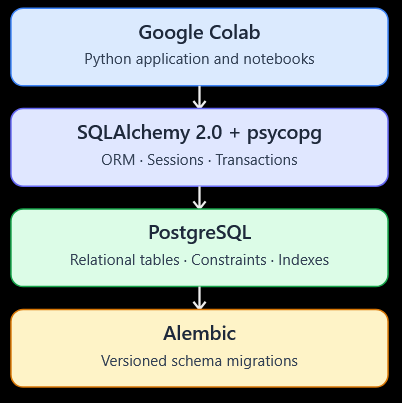

By the end, you'll know how to create a PostgreSQL database in Colab, connect SQLAlchemy with psycopg, create versioned Alembic migrations, upgrade and downgrade database schemas, add indexes and constraints, and inspect generated SQL.

**Phase 1 — PostgreSQL setup in Google Colab**

**Step 1. Install PostgreSQL and Python libraries**

In [ ]:

!apt-get update -qq
!apt-get install -y -qq postgresql postgresql-contrib > /dev/null

%pip -q install "sqlalchemy>=2.0,<3" "psycopg[binary]" alembic pandas numpy plotly

print("PostgreSQL and Python packages installed")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 14.9 MB/s eta 0:00:00
PostgreSQL and Python packages installed


**Notes:** PostgreSQL is a separate database server, unlike SQLite, which is embedded in Python. psycopg is the PostgreSQL driver, and Alembic manages schema changes over time.

This installation is temporary. Google Colab may reset its runtime and erase the local PostgreSQL database.

**Step 2. Start the PostgreSQL service**

In [ ]:

import subprocess

subprocess.run(
    ["service", "postgresql", "start"],
    check=True
)

result = subprocess.run(
    ["pg_lsclusters"],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)


Ver Cluster Port Status Owner    Data directory              Log file
16  main    5432 online postgres /var/lib/postgresql/16/main /var/log/postgresql/postgresql-16-main.log



The PostgreSQL version may differ depending on Colab's operating system.

**Step 3. Create a database and user**

In [ ]:

import subprocess
import secrets

DB_NAME = "financial_risk"
DB_USER = "risk_app"
DB_PASSWORD = secrets.token_urlsafe(24)

def run_postgres(sql):
    return subprocess.run(
        ["runuser", "-u", "postgres", "--",
         "psql", "-v", "ON_ERROR_STOP=1", "-c", sql],
        capture_output=True,
        text=True,
        check=True
    )

# Create a dedicated database role
run_postgres(
    f"CREATE ROLE {DB_USER} LOGIN PASSWORD '{DB_PASSWORD}'"
)

# Create a database owned by this role
run_postgres(
    f"CREATE DATABASE {DB_NAME} OWNER {DB_USER}"
)

print("Database created:", DB_NAME)
print("Application user created:", DB_USER)


Database created: financial_risk
Application user created: risk_app


**Notes:** This cell assumes a fresh PostgreSQL installation. If you rerun it in the same runtime, PostgreSQL will report that the role already exists. Use a fresh runtime or skip this cell after successful creation.

For a production system, use a secrets manager and separate roles for migrations and application access. Here the credentials are generated for an isolated Colab environment.

**Step 4. Connect SQLAlchemy to PostgreSQL**

In [ ]:

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sqlalchemy.orm import sessionmaker

DATABASE_URL = URL.create(
    drivername="postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host="localhost",
    port=5432,
    database=DB_NAME
)

engine = create_engine(
    DATABASE_URL,
    echo=False,
    pool_pre_ping=True,
    pool_size=5,
    max_overflow=10
)

SessionLocal = sessionmaker(
    bind=engine,
    expire_on_commit=False
)

with engine.connect() as conn:
    version = conn.scalar(text("SELECT version()"))
    database = conn.scalar(
        text("SELECT current_database()")
    )

print("Connected database:", database)
print("PostgreSQL:", version.split(",")[0])


Connected database: financial_risk
PostgreSQL: PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04.1) on x86_64-pc-linux-gnu


**Notes:** pool_size=5 retains up to five connections in the pool, while max_overflow=10 allows up to ten additional temporary connections under load. These are demonstration settings, not necessarily optimal production values.

**Phase 2 — Create production-style SQLAlchemy models**

Instead of defining models only inside notebook cells, we'll save them to a Python module. This allows both SQLAlchemy and Alembic to import the same model definitions.

**Step 5. Create the project structure**

In [ ]:

from pathlib import Path
import os

PROJECT_DIR = Path("/content/financial_risk_platform")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)

print("Working directory:", os.getcwd())


Working directory: /content/financial_risk_platform


financial_risk_platform/

│

├── models.py

├── database.py

├── alembic.ini

│

└── alembic/

    ├── env.py

    ├── script.py.mako

    └── versions/

        ├── xxxx_initial_schema.py

        └── xxxx_add_risk_level.py


In [ ]:

%%writefile models.py
from datetime import datetime
from decimal import Decimal

from sqlalchemy import (
    String, ForeignKey, Numeric, DateTime,
    CheckConstraint, Index, func
)
from sqlalchemy.orm import (
    DeclarativeBase, Mapped,
    mapped_column, relationship
)


class Base(DeclarativeBase):
    pass


class Customer(Base):
    __tablename__ = "customers"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    email: Mapped[str] = mapped_column(
        String(180), unique=True
    )
    country: Mapped[str] = mapped_column(String(2))

    accounts: Mapped[list["Account"]] = relationship(
        back_populates="customer"
    )


class Account(Base):
    __tablename__ = "accounts"

    id: Mapped[int] = mapped_column(primary_key=True)
    customer_id: Mapped[int] = mapped_column(
        ForeignKey("customers.id"), index=True
    )
    balance: Mapped[Decimal] = mapped_column(
        Numeric(18, 2), default=Decimal("0.00")
    )
    currency: Mapped[str] = mapped_column(
        String(3), default="EUR"
    )

    customer: Mapped["Customer"] = relationship(
        back_populates="accounts"
    )
    transactions: Mapped[list["Transaction"]] = relationship(
        back_populates="account"
    )


class Merchant(Base):
    __tablename__ = "merchants"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    category: Mapped[str] = mapped_column(String(60))
    country: Mapped[str] = mapped_column(String(2))

    transactions: Mapped[list["Transaction"]] = relationship(
        back_populates="merchant"
    )


class Transaction(Base):
    __tablename__ = "transactions"

    id: Mapped[int] = mapped_column(primary_key=True)
    account_id: Mapped[int] = mapped_column(
        ForeignKey("accounts.id")
    )
    merchant_id: Mapped[int] = mapped_column(
        ForeignKey("merchants.id")
    )
    amount: Mapped[Decimal] = mapped_column(
        Numeric(18, 2)
    )
    created_at: Mapped[datetime] = mapped_column(
        DateTime(timezone=True),
        server_default=func.now()
    )
    status: Mapped[str] = mapped_column(
        String(20), server_default="completed"
    )

    account: Mapped["Account"] = relationship(
        back_populates="transactions"
    )
    merchant: Mapped["Merchant"] = relationship(
        back_populates="transactions"
    )
    alerts: Mapped[list["FraudAlert"]] = relationship(
        back_populates="transaction"
    )

    __table_args__ = (
        CheckConstraint(
            "amount > 0",
            name="ck_transaction_positive_amount"
        ),
        Index(
            "ix_transaction_account_date",
            "account_id", "created_at"
        ),
    )


class FraudAlert(Base):
    __tablename__ = "fraud_alerts"

    id: Mapped[int] = mapped_column(primary_key=True)
    transaction_id: Mapped[int] = mapped_column(
        ForeignKey("transactions.id"), unique=True
    )
    risk_score: Mapped[Decimal] = mapped_column(
        Numeric(8, 5)
    )
    severity: Mapped[str] = mapped_column(String(20))

    transaction: Mapped["Transaction"] = relationship(
        back_populates="alerts"
    )


Writing models.py


**Important notes**

•	server_default=func.now() tells PostgreSQL to generate timestamps.

•	Numeric(18, 2) stores decimal values with two decimal places.

•	CheckConstraint enforces valid amounts at the database level.

•	Index creates an index for queries involving account and date.

•	Mapped[...] is SQLAlchemy 2.0's typed declarative ORM syntax.

Notice that we have not called Base.metadata.create_all(engine). From now on, Alembic will be responsible for creating and updating database tables.

**Step 7. Create a reusable database module**



In [ ]:

%%writefile database.py
import os

from sqlalchemy import create_engine
from sqlalchemy.orm import sessionmaker

DATABASE_URL = os.environ["DATABASE_URL"]

engine = create_engine(
    DATABASE_URL,
    pool_pre_ping=True,
    pool_size=5,
    max_overflow=10
)

SessionLocal = sessionmaker(
    bind=engine,
    expire_on_commit=False
)


def get_session():
    with SessionLocal() as session:
        yield session


Writing database.py


**Set the database connection string for the Python modules and Alembic.**

In [ ]:

os.environ["DATABASE_URL"] = (
    DATABASE_URL.render_as_string(
        hide_password=False
    )
)

print("Database connection configured")


Database connection configured


The environment variable is used by database.py and the migration environment. Avoid printing the full connection URL because it contains the password.

**Phase 3 — Initialize Alembic**

Alembic is a database migration framework. It tracks changes to your database structure and lets you upgrade or downgrade between schema versions.

**Step 8. Initialize the migration environment**

In [ ]:

import subprocess

result = subprocess.run(
    ["alembic", "init", "alembic"],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)


Creating directory /content/financial_risk_platform/alembic ...  done
Creating directory /content/financial_risk_platform/alembic/versions ...  done
Generating /content/financial_risk_platform/alembic/env.py ...  done
Generating /content/financial_risk_platform/alembic/script.py.mako ...  done
Generating /content/financial_risk_platform/alembic/README ...  done
Generating /content/financial_risk_platform/alembic.ini ...  done
Please edit configuration/connection/logging settings in /content/financial_risk_platform/alembic.ini before proceeding.



Run this initialization only once per project directory.

**Step 9. Configure Alembic to discover ORM models**

Alembic needs to know two things: which database to connect to, and which SQLAlchemy models represent the desired schema.

We'll replace the generated alembic/env.py with a version that reads the database URL from the environment.

In [ ]:

%%writefile alembic/env.py
import os

from logging.config import fileConfig

from sqlalchemy import engine_from_config, pool
from alembic import context

from models import Base

config = context.config

if config.config_file_name is not None:
    fileConfig(config.config_file_name)

target_metadata = Base.metadata


def run_migrations_offline():
    url = os.environ["DATABASE_URL"]

    context.configure(
        url=url,
        target_metadata=target_metadata,
        literal_binds=True,
        dialect_opts={"paramstyle": "named"},
        compare_type=True
    )

    with context.begin_transaction():
        context.run_migrations()


def run_migrations_online():
    configuration = config.get_section(
        config.config_ini_section, {}
    ).copy()

    configuration["sqlalchemy.url"] = (
        os.environ["DATABASE_URL"]
    )

    connectable = engine_from_config(
        configuration,
        prefix="sqlalchemy.",
        poolclass=pool.NullPool
    )

    with connectable.connect() as connection:
        context.configure(
            connection=connection,
            target_metadata=target_metadata,
            compare_type=True
        )

        with context.begin_transaction():
            context.run_migrations()


if context.is_offline_mode():
    run_migrations_offline()
else:
    run_migrations_online()


Overwriting alembic/env.py


**Notes:** target_metadata = Base.metadata allows Alembic to inspect all registered SQLAlchemy models. compare_type=True helps identify column type changes. pool.NullPool avoids retaining connections in the short-lived migration process.

Alembic autogeneration is useful, but it is not infallible. Always inspect migration files before applying them.

**Phase 4 — Create and apply the first migration**

**Step 10. Generate the initial migration**

In [ ]:

result = subprocess.run(
    [
        "alembic", "revision",
        "--autogenerate",
        "-m", "initial_schema"
    ],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)


Generating /content/financial_risk_platform/alembic/versions/aaaf52c7fcee_initial_schema.py ...  done



Alembic compares the empty PostgreSQL schema with your SQLAlchemy models and generates a migration script.

**Step 11. Inspect the generated migration**

In [ ]:

migration_files = sorted(
    Path("alembic/versions").glob("*.py")
)

for path in migration_files:
    print(f"\n--- {path.name} ---")
    print(path.read_text()[:12000])



--- aaaf52c7fcee_initial_schema.py ---
"""initial_schema

Revision ID: aaaf52c7fcee
Revises: 
Create Date: 2026-10-22 13:11:24.496164

"""
from typing import Sequence, Union

from alembic import op
import sqlalchemy as sa


# revision identifiers, used by Alembic.
revision: str = 'aaaf52c7fcee'
down_revision: Union[str, Sequence[str], None] = None
branch_labels: Union[str, Sequence[str], None] = None
depends_on: Union[str, Sequence[str], None] = None


def upgrade() -> None:
    """Upgrade schema."""
    # ### commands auto generated by Alembic - please adjust! ###
    op.create_table('customers',
    sa.Column('id', sa.Integer(), nullable=False),
    sa.Column('name', sa.String(length=120), nullable=False),
    sa.Column('email', sa.String(length=180), nullable=False),
    sa.Column('country', sa.String(length=2), nullable=False),
    sa.PrimaryKeyConstraint('id'),
    sa.UniqueConstraint('email')
    )
    op.create_table('merchants',
    sa.Column('id', sa.Integer(), nullable=False

You should see operations similar to:

In [ ]:
def upgrade():
    op.create_table(
        "customers",
        sa.Column("id", sa.Integer(), nullable=False),
        ...
    )

The generated file should include creation of all five tables, primary keys, foreign keys, constraints, and indexes.

**Step 12. Apply the migration**

In [ ]:

result = subprocess.run(
    ["alembic", "upgrade", "head"],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)
print(result.stderr[-1500:])



INFO  [alembic.runtime.migration] Context impl PostgresqlImpl.
INFO  [alembic.runtime.migration] Will assume transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> aaaf52c7fcee, initial_schema



head refers to the latest migration revision.

**Step 13. Verify the PostgreSQL schema**

In [ ]:

from sqlalchemy import inspect

inspector = inspect(engine)

for table_name in inspector.get_table_names():
    print("\nTABLE:", table_name)

    for col in inspector.get_columns(table_name):
        print(
            "  ", col["name"],
            col["type"]
        )



TABLE: alembic_version
   version_num VARCHAR(32)

TABLE: customers
   id INTEGER
   name VARCHAR(120)
   email VARCHAR(180)
   country VARCHAR(2)

TABLE: accounts
   id INTEGER
   customer_id INTEGER
   balance NUMERIC(18, 2)
   currency VARCHAR(3)

TABLE: transactions
   id INTEGER
   account_id INTEGER
   merchant_id INTEGER
   amount NUMERIC(18, 2)
   created_at TIMESTAMP
   status VARCHAR(20)

TABLE: merchants
   id INTEGER
   name VARCHAR(120)
   category VARCHAR(60)
   country VARCHAR(2)

TABLE: fraud_alerts
   id INTEGER
   transaction_id INTEGER
   risk_score NUMERIC(8, 5)
   severity VARCHAR(20)


The additional alembic_version table stores the current database migration revision.

**Phase 5 — Schema evolution: Add a new column**

Imagine that the fraud detection team introduces a new requirement:
Every transaction must have a risk level: LOW, MEDIUM, or HIGH.

We should not manually change the PostgreSQL database. Instead, we'll modify our SQLAlchemy model and generate a new Alembic migration.

**Step 14. Modify the Transaction model**

In [ ]:

from pathlib import Path

model_path = Path("models.py")
source = model_path.read_text()

old = '''    status: Mapped[str] = mapped_column(
        String(20), server_default="completed"
    )
'''

new = '''    status: Mapped[str] = mapped_column(
        String(20), server_default="completed"
    )
    risk_level: Mapped[str] = mapped_column(
        String(20),
        server_default="LOW"
    )
'''

assert old in source, "Expected model definition not found"
model_path.write_text(source.replace(old, new, 1))

print("Transaction model updated")


Transaction model updated


**Notes:** server_default="LOW" is important when adding a non-nullable column to a table that may already contain data. PostgreSQL can provide the default for existing rows.

**Step 15. Generate a second migration**

In [ ]:

result = subprocess.run(
    [
        "alembic", "revision",
        "--autogenerate",
        "-m", "add_transaction_risk_level"
    ],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)


Generating /content/financial_risk_platform/alembic/versions/0a8c2d796f5f_add_transaction_risk_level.py ...  done



Inspect the newest migration.

In [ ]:

migration_files = list(
    Path("alembic/versions").glob("*.py")
)

latest = max(
    migration_files,
    key=lambda p: p.stat().st_mtime_ns
)

print(latest.read_text())


"""add_transaction_risk_level

Revision ID: 0a8c2d796f5f
Revises: aaaf52c7fcee
Create Date: 2026-10-22 13:15:09.596690

"""
from typing import Sequence, Union

from alembic import op
import sqlalchemy as sa


# revision identifiers, used by Alembic.
revision: str = '0a8c2d796f5f'
down_revision: Union[str, Sequence[str], None] = 'aaaf52c7fcee'
branch_labels: Union[str, Sequence[str], None] = None
depends_on: Union[str, Sequence[str], None] = None


def upgrade() -> None:
    """Upgrade schema."""
    # ### commands auto generated by Alembic - please adjust! ###
    op.add_column('transactions', sa.Column('risk_level', sa.String(length=20), server_default='LOW', nullable=False))
    # ### end Alembic commands ###


def downgrade() -> None:
    """Downgrade schema."""
    # ### commands auto generated by Alembic - please adjust! ###
    op.drop_column('transactions', 'risk_level')
    # ### end Alembic commands ###



Inspect the newest migration.

In [ ]:

migration_files = list(
    Path("alembic/versions").glob("*.py")
)

latest = max(
    migration_files,
    key=lambda p: p.stat().st_mtime_ns
)

print(latest.read_text())


"""add_transaction_risk_level

Revision ID: 0a8c2d796f5f
Revises: aaaf52c7fcee
Create Date: 2026-10-22 13:15:09.596690

"""
from typing import Sequence, Union

from alembic import op
import sqlalchemy as sa


# revision identifiers, used by Alembic.
revision: str = '0a8c2d796f5f'
down_revision: Union[str, Sequence[str], None] = 'aaaf52c7fcee'
branch_labels: Union[str, Sequence[str], None] = None
depends_on: Union[str, Sequence[str], None] = None


def upgrade() -> None:
    """Upgrade schema."""
    # ### commands auto generated by Alembic - please adjust! ###
    op.add_column('transactions', sa.Column('risk_level', sa.String(length=20), server_default='LOW', nullable=False))
    # ### end Alembic commands ###


def downgrade() -> None:
    """Downgrade schema."""
    # ### commands auto generated by Alembic - please adjust! ###
    op.drop_column('transactions', 'risk_level')
    # ### end Alembic commands ###



The migration should contain an operation similar to:

In [ ]:
def upgrade():
    op.add_column(
        "transactions",
        sa.Column(
            "risk_level",
            sa.String(length=20),
            server_default="LOW",
            nullable=False
        )
    )

def downgrade():
    op.drop_column(
        "transactions",
        "risk_level"
    )

**Step 16. Upgrade the database**

In [ ]:

subprocess.run(
    ["alembic", "upgrade", "head"],
    check=True
)

from sqlalchemy import inspect

columns = inspect(engine).get_columns("transactions")

for col in columns:
    print(col["name"], col["type"])


id INTEGER
account_id INTEGER
merchant_id INTEGER
amount NUMERIC(18, 2)
created_at TIMESTAMP
status VARCHAR(20)
risk_level VARCHAR(20)


You should now see risk_level in the transactions table.

**Phase 6 — Insert and query PostgreSQL data**

**Step 17. Insert sample data using a transaction**

In [ ]:

from decimal import Decimal
from datetime import datetime, timezone

from models import (
    Customer, Account, Merchant,
    Transaction, FraudAlert
)
from database import SessionLocal

with SessionLocal.begin() as session:
    customer = Customer(
        name="John Smith",
        email="john.smith@example.com",
        country="GR"
    )
    session.add(customer)
    session.flush()

    account = Account(
        customer_id=customer.id,
        balance=Decimal("15000.00"),
        currency="EUR"
    )

    merchant = Merchant(
        name="Athens Electronics",
        category="Electronics",
        country="GR"
    )

    session.add_all([account, merchant])
    session.flush()

    transaction = Transaction(
        account_id=account.id,
        merchant_id=merchant.id,
        amount=Decimal("2499.99"),
        created_at=datetime.now(timezone.utc),
        status="completed",
        risk_level="HIGH"
    )

    session.add(transaction)

print("Customer, account, merchant and transaction saved")


Customer, account, merchant and transaction saved


This is an atomic database transaction: if any operation raises an exception, the entire block rolls back.

The sample transaction's HIGH risk level is manually assigned for demonstration; it is not the output of a fraud detection model.

**Step 18. Query PostgreSQL using SQLAlchemy**

In [ ]:

from sqlalchemy import select

stmt = (
    select(
        Customer.name.label("customer"),
        Merchant.name.label("merchant"),
        Transaction.amount,
        Transaction.risk_level
    )
    .join(Account, Customer.id == Account.customer_id)
    .join(Transaction, Account.id == Transaction.account_id)
    .join(Merchant, Transaction.merchant_id == Merchant.id)
    .where(Transaction.risk_level == "HIGH")
)

with SessionLocal() as session:
    results = session.execute(stmt).mappings().all()

import pandas as pd

display(pd.DataFrame(results))


,amount,customer,merchant,risk_level
0,2499.99,John Smith,Athens Electronics,HIGH


**Step 19. PostgreSQL-specific SQL**

Unlike SQLite, PostgreSQL supports features such as FILTER on aggregate expressions.

In [ ]:

from sqlalchemy import func, select

stmt = select(
    func.count(Transaction.id).label("total"),
    func.count(Transaction.id)
        .filter(Transaction.risk_level == "HIGH")
        .label("high_risk"),
    func.sum(Transaction.amount)
        .filter(Transaction.risk_level == "HIGH")
        .label("high_risk_volume")
)

with SessionLocal() as session:
    result = session.execute(stmt).one()

print("Total transactions:", result.total)
print("High-risk transactions:", result.high_risk)
print("High-risk volume:", result.high_risk_volume)


Total transactions: 1
High-risk transactions: 1
High-risk volume: 2499.99


**Generated SQL concept:**

SELECT
    COUNT(id) AS total,
    COUNT(id) FILTER (
        WHERE risk_level = 'HIGH'
    ) AS high_risk,
    SUM(amount) FILTER (
        WHERE risk_level = 'HIGH'
    ) AS high_risk_volume
FROM transactions;

This technique is useful for reporting and financial dashboards.

**Phase 7 — Alembic rollback and migration history**

**Step 20. Inspect migration history**

In [ ]:

for command in [
    ["alembic", "history", "--verbose"],
    ["alembic", "current"],
    ["alembic", "heads"]
]:
    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        check=True
    )

    print("\n$", " ".join(command))
    print(result.stdout)



$ alembic history --verbose
Rev: 0a8c2d796f5f (head)
Parent: aaaf52c7fcee
Path: /content/financial_risk_platform/alembic/versions/0a8c2d796f5f_add_transaction_risk_level.py

    add_transaction_risk_level
    
    Revision ID: 0a8c2d796f5f
    Revises: aaaf52c7fcee
    Create Date: 2026-10-22 13:15:09.596690

Rev: aaaf52c7fcee
Parent: <base>
Path: /content/financial_risk_platform/alembic/versions/aaaf52c7fcee_initial_schema.py

    initial_schema
    
    Revision ID: aaaf52c7fcee
    Revises: 
    Create Date: 2026-10-22 13:11:24.496164



$ alembic current
0a8c2d796f5f (head)


$ alembic heads
0a8c2d796f5f (head)



These commands show the migration history, the revision currently applied to PostgreSQL, and the latest revision available in the project.

**Step 21. Test a downgrade**

Alembic supports reversing schema changes when a migration has a valid downgrade() implementation.

In [ ]:

# Demonstration only: removes the risk_level column.
subprocess.run(
    ["alembic", "downgrade", "-1"],
    check=True
)

columns = inspect(engine).get_columns("transactions")
print([col["name"] for col in columns])


['id', 'account_id', 'merchant_id', 'amount', 'created_at', 'status']


**Warning:** Downgrading this migration removes the risk_level column and its stored values. Use this only in the disposable Colab database, not against a production database without a backup and rollback plan.

**Step 22. Restore the latest schema**

In [ ]:

subprocess.run(
    ["alembic", "upgrade", "head"],
    check=True
)

columns = inspect(engine).get_columns("transactions")

print([col["name"] for col in columns])
print("Database restored to latest schema")


['id', 'account_id', 'merchant_id', 'amount', 'created_at', 'status', 'risk_level']
Database restored to latest schema


After restoration, existing transactions will receive the default risk level LOW, including any transaction that previously had HIGH.

**Phase 8 — PostgreSQL performance analysis**

**Step 23. Use EXPLAIN ANALYZE**

In [ ]:

from sqlalchemy import text

query = text("""
    EXPLAIN (ANALYZE, BUFFERS)
    SELECT *
    FROM transactions
    WHERE account_id = :account_id
    ORDER BY created_at DESC
    LIMIT 20
""")

with engine.connect() as conn:
    plan = conn.execute(
        query, {"account_id": 1}
    ).scalars().all()

for line in plan:
    print(line)


Limit  (cost=9.51..9.52 rows=2 width=156) (actual time=0.038..0.040 rows=1 loops=1)
  Buffers: shared hit=8
  ->  Sort  (cost=9.51..9.52 rows=2 width=156) (actual time=0.037..0.038 rows=1 loops=1)
        Sort Key: created_at DESC
        Sort Method: quicksort  Memory: 25kB
        Buffers: shared hit=8
        ->  Bitmap Heap Scan on transactions  (cost=4.16..9.50 rows=2 width=156) (actual time=0.018..0.019 rows=1 loops=1)
              Recheck Cond: (account_id = '1'::smallint)
              Heap Blocks: exact=1
              Buffers: shared hit=5
              ->  Bitmap Index Scan on ix_transaction_account_date  (cost=0.00..4.16 rows=2 width=0) (actual time=0.011..0.011 rows=1 loops=1)
                    Index Cond: (account_id = '1'::smallint)
                    Buffers: shared hit=4
Planning:
  Buffers: shared hit=66
Planning Time: 0.390 ms
Execution Time: 0.070 ms


Look for:
- Index Scan or Bitmap Index Scan: PostgreSQL uses an index.
- Seq Scan: PostgreSQL scans the table.
- Execution Time: Actual query execution duration.
- Buffers: Database page access information.

A sequential scan is not always bad. For small tables, PostgreSQL may correctly choose it instead of using an index.
